# M03 - Random Forest
Clasificación NOVA (1-4) con Random Forest. Issue #10.

**Qué es un Random Forest:** un conjunto de muchos árboles de decisión, cada uno entrenado con una muestra distinta de productos y de variables. Cada árbol vota una clase y gana la mayoría. Al combinar muchos árboles se equivoca menos y sobreajusta menos que un árbol solo.

**Reglas del equipo que seguimos:**
- Entrenamos solo con train (columna `split`). El test se usa una sola vez, al final en M08.
- Métrica principal: macro F1, más el recall por clase (sobre todo NOVA 2).
- Gap entre train y validación por debajo del 5%.

## Paso 1 - Carga del dataset

Cargamos el CSV limpio compartido. Usamos `dtype={"code": str}` para que los códigos de barras se lean como texto y no pierdan los ceros a la izquierda.

In [1]:
import pandas as pd

# Cargamos el dataset limpio compartido.
df = pd.read_csv("../data/processed/off_nova_clean.csv.gz", dtype={"code": str})

print(df.shape)
df["split"].value_counts()

(48119, 35)


split
train    38495
test      9624
Name: count, dtype: int64

In [2]:
train = df[df["split"] == "train"]
test = df[df["split"] == "test"]

pd.crosstab(df["split"], df["nova_group"], normalize="index").round(3)

nova_group,1,2,3,4
split,,,,
test,0.129,0.112,0.204,0.555
train,0.129,0.112,0.204,0.555


### 2.1 Resultados

- 48.119 productos: 38.495 en train (80%) y 9.624 en test (20%).
- Las proporciones de NOVA son iguales en train y test (12,9 / 11,2 / 20,4 / 55,5 %): el split está estratificado.
- NOVA 4 es más de la mitad de los datos. Por eso no usamos accuracy como métrica principal: un modelo que dijera siempre "NOVA 4" acertaría el 55 % sin aprender nada.

## Paso 3 - Variables del modelo

No todas las columnas sirven para predecir. Siguiendo las decisiones del EDA (E01/E02), **quitamos**:

- **Identificadores y texto:** `code`, `product_name`, `brands`, `ingredients_text`. Son nombres o texto libre; el modelo memorizaría productos concretos en vez de aprender patrones. La información útil de los ingredientes ya está resumida en los marcadores `tiene_*`.
- **`grupo_producto`:** no es variable, pero lo guardamos aparte para agrupar en la validación cruzada (paso 5).
- **`split`:**  solo indica si la fila es de train o test.
- **`nova_group`:** es l;o que queremos predecir (lavariable objetivo, `y`).
- **`pnns_groups_1`:** usamos `pnns_groups_2`, que es la misma categoría pero más detallada. 
- **`tiene_grasa_hidrogenada`:** solo aparece en el 0,5% de los productos, aporta casi nada.

Nos quedan **25 variables numéricas** (nutrientes, aditivos y marcadores `tiene_*`) y **1 categórica** (`pnns_groups_2`).

In [3]:
# Variables numéricas: nutrientes por 100 g, conteos y marcadores de ingredientes (0/1)
num_cols = [
    "additives_n", "n_ingredientes", "sin_lista_ingredientes",
    "energy-kcal_100g", "fat_100g", "saturated-fat_100g", "carbohydrates_100g",
    "sugars_100g", "fiber_100g", "proteins_100g", "salt_100g",
    "fruits-vegetables-legumes_100g",
    "tiene_aromas", "tiene_edulcorantes", "tiene_jarabes", "tiene_almidon_modificado",
    "tiene_proteina_aislada", "tiene_colorantes", "tiene_emulsionantes",
    "tiene_potenciadores", "tiene_aceite_palma", "tiene_conservantes",
    "tiene_sal", "tiene_azucar", "tiene_aceite",
]

# Variable categórica: categoría del producto
cat_cols = ["pnns_groups_2"]

# X = lo que ve el modelo, y = lo que tiene que predecir
X_train = train[num_cols + cat_cols]
y_train = train["nova_group"]

# Grupos para la validación cruzada: mismo nombre + marca = mismo grupo
groups_train = train["grupo_producto"]

print("X_train:", X_train.shape)
print("Grupos distintos:", groups_train.nunique())

# Valores faltantes por columna (solo las que tienen alguno)
X_train.isna().sum()[lambda s: s > 0].sort_values(ascending=False)

X_train: (38495, 26)
Grupos distintos: 37052


fiber_100g                        12928
fruits-vegetables-legumes_100g     4314
saturated-fat_100g                 1178
sugars_100g                        1082
salt_100g                          1079
fat_100g                            800
proteins_100g                       793
carbohydrates_100g                  789
energy-kcal_100g                    482
additives_n                           3
n_ingredientes                        2
dtype: int64

### 3.1 Resultados

- `X_train` tiene 38.495 productos y 26 variables (25 numéricas + 1 categórica).
- Hay 37.052 grupos distintos: casi todos los productos son únicos, pero algunos se repiten (mismo nombre y marca). El paso 5 explica por qué esto importa.
- **Faltan valores en 11 columnas**, no solo en la fibra:
  - `fiber_100g`: ~34 % de faltantes (muchas etiquetas no la declaran).
  - `fruits-vegetables-legumes_100g`: ~11 %.
  - Los demás nutrientes: entre 1 y 3 %.
- El issue solo indica cómo imputar la fibra, así que hay que decidir qué hacer con el resto. Lo resolvemos en el paso 4.

## Paso 4 · Pipeline de preprocesado + modelo

Un `Pipeline` encadena el preprocesado y el modelo en un solo objeto. Ventajas:
- En la validación cruzada se reajusta entero en cada fold, usando solo los datos de entrenamiento de ese fold. Así no hay fuga de información (*data leakage*) desde validación.
- Se guarda entero con `joblib`, así que la app puede predecir a partir de valores en bruto sin preprocesar nada por su cuenta (requisito de M08 y A04).

**Preprocesado** (`ColumnTransformer`, que aplica un tratamiento distinto a cada tipo de columna):
- **Numéricas:** imputamos los faltantes con la **mediana** y añadimos una columna indicadora (`add_indicator=True`) que vale 1 si el valor faltaba.
  - El issue lo indica para la fibra (~34 % de faltantes). **Decisión nuestra:** aplicamos la misma regla a todas las numéricas con faltantes (otras 10 columnas, entre 0,01 % y 11 %), por coherencia.
  - No escalamos ni aplicamos logaritmos: los árboles comparan umbrales ("¿azúcar > 10 g?") y la escala no les afecta.
- **Categórica (`pnns_groups_2`):** `OneHotEncoder` crea una columna 0/1 por categoría.
  - `min_frequency=50`: las categorías con menos de 50 productos se agrupan en una sola "infrecuente".
  - `handle_unknown="infrequent_if_exist"`: si en test o en la app aparece una categoría nueva, va a esa columna en vez de dar error.

**Modelo:** `RandomForestClassifier` con `class_weight="balanced"`, que da más peso a las clases pequeñas (NOVA 2) para que el modelo no las ignore. `random_state=42` hace que los resultados sean reproducibles.

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

# Preprocesado: un tratamiento distinto para cada tipo de columna
preprocesado = ColumnTransformer([
    # Numéricas: rellenar faltantes con la mediana + columna indicadora de "faltaba"
    ("num", SimpleImputer(strategy="median", add_indicator=True), num_cols),
    # Categórica: una columna 0/1 por categoría; las raras (<50) se agrupan
    ("cat", OneHotEncoder(min_frequency=50, handle_unknown="infrequent_if_exist", sparse_output=False), cat_cols),])

# Pipeline completo: preprocesado + Random Forest
modelo = Pipeline([
    ("pre", preprocesado),
    ("rf", RandomForestClassifier(
        n_estimators=200,           # de árboles del bosque
        class_weight="balanced",    # más peso a las clases pequeñas (NOVA 2)
        random_state=42,            # resultados reproducibles
        n_jobs=1,                   # usa todos los núcleos del ordenador
    )),
])

# Comprobación: cuántas columnas salen del preprocesado
# (fit_transform sobre train solo para inspeccionar; el entrenamiento real va en el paso 5)
X_prep = preprocesado.fit_transform(X_train)
print("Columnas tras el preprocesado:", X_prep.shape[1])

modelo


Columnas tras el preprocesado: 76


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('rf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of t

### 4.1 Resultados

Las 26 variables se convierten en **76 columnas**:
- 25 numéricas (con los faltantes ya rellenos).
- 11 indicadoras de "faltaba el valor" (una por cada columna con faltantes).
- 40 de la categoría: 39 categorías frecuentes + 1 "infrecuente", que agrupa *Fruit nectars* (35), *Baby milks* (26) y *Offals* (15).

Todavía no hemos limitado `max_depth` ni `min_samples_leaf`. Primero medimos cuánto sobreajusta el modelo por defecto (paso 5) y después lo ajustamos (paso 6).

## Paso 5 - Validación cruzada agrupada y gap

Para saber cómo se comportará el modelo con productos que nunca ha visto, sin tocar el testo, usamos **validación cruzada** dentro de train:
1. Dividimos train en 5 partes (**folds**).
2. Entrenamos con 4 y validamos con la que queda.
3. Repetimos 5 veces, cambiando la parte de validación, y promediamos.

**Por qué `StratifiedGroupKFold`:**
- **Stratified:** cada fold mantiene la proporción de clases NOVA.
- **Group:** todos los productos con el mismo `grupo_producto` (nombre + marca) caen en el mismo fold. Si el mismo producto apareciera en entrenamiento y en validación, el modelo "lo reconocería" y la nota saldría inflada.

**Gap** = macro F1 en train - macro F1 en validación. Mide el sobreajuste: un modelo que memoriza saca casi un 100% en train y bastante menos en validación. El limite del equipo es **< 5%**.

Primero medimos el modelo **sin límites** (árboles que crecen hasta el final) como punto de partida.

In [5]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate

# 5 folds estratificados y agrupados por producto; random_state para que sea reproducible
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# Entrena y evalúa el pipeline 5 veces.
# return_train_score=True también calcula la nota en train, que necesitamos para el gap
resultados = cross_validate(
    modelo, X_train, y_train,
    groups=groups_train,
    cv=cv,
    scoring="f1_macro",
    return_train_score=True,
)

# Tabla con la nota de cada fold y su gap
tabla_cv = pd.DataFrame({
    "f1_train": resultados["train_score"],
    "f1_val": resultados["test_score"],
})
tabla_cv["gap"] = tabla_cv["f1_train"] - tabla_cv["f1_val"]

print(tabla_cv.round(4))
print("\nMedia:")
print(tabla_cv.mean().round(4))

   f1_train  f1_val     gap
0    0.9916  0.9561  0.0355
1    0.9910  0.9618  0.0291
2    0.9913  0.9633  0.0280
3    0.9914  0.9602  0.0312
4    0.9914  0.9623  0.0291

Media:
f1_train    0.9913
f1_val      0.9607
gap         0.0306
dtype: float64


### 5.1 Resultados (modelo sin límites)

| | Macro F1 |
|---|---|
| Train | 0,991 |
| Validación (CV) | 0,961 |
| **Gap** | **3,0 %** ✅ |

- El gap ya está por debajo del 5 % sin limitar el modelo. Un Random Forest sobreajusta menos que un árbol solo: cada árbol memoriza su muestra, pero al promediar muchos los errores se compensan.
- Los 5 folds dan resultados muy parecidos (validación entre 0,956 y 0,963): el resultado es estable.
- Aun así, el issue pide limitar `max_depth` y `min_samples_leaf`. En el paso 6 probamos varios valores para ver si el gap baja sin perder F1 en validación.

## Paso 6 - Limitar la complejidad (`max_depth`, `min_samples_leaf`)

Dos "frenos" contra el sobreajuste:
- `max_depth`: profundidad máxima de cada árbol (cuántas preguntas seguidas puede hacer). `None` = sin límite.
- `min_samples_leaf`: mínimo de productos en cada hoja(respuesta final). Con 1, un árbol puede crear una regla para un solo producto.

`GridSearchCV` prueba todas las combinaciones con la misma validación cruzada agrupada del paso 5 y guarda la nota de train y de validación de cada una, así podemos calcular el gap.

Criterio para elegir: el mejor **macro F1 en validación** con un **gap <5%**.

In [6]:
from sklearn.model_selection import GridSearchCV

# Combinaciones a probar. "rf__" indica que el parámetro es del paso "rf" del pipeline
parametros = {
    "rf__max_depth": [None, 20, 15, 10],
    "rf__min_samples_leaf": [1, 5, 10],
}

busqueda = GridSearchCV(
    modelo, parametros,
    cv=cv,
    scoring="f1_macro",
    return_train_score=True,
)
busqueda.fit(X_train, y_train, groups=groups_train)   # 12 combinaciones x 5 folds = 60 entrenamientos

# Tabla resumen ordenada de mejor a peor F1 en validación
res =  pd.DataFrame(busqueda.cv_results_)
tabla_grid = pd.DataFrame({
    "max_depth": res["param_rf__max_depth"],
    "min_samples_leaf": res["param_rf__min_samples_leaf"],
    "f1_train": res["mean_train_score"],
    "f1_val": res["mean_test_score"],
})
tabla_grid["gap"] = tabla_grid["f1_train"] - tabla_grid["f1_val"]
tabla_grid.sort_values("f1_val", ascending=False).round(4)

,max_depth,min_samples_leaf,f1_train,f1_val,gap
0,None,1,0.9913,0.9607,0.0306
3,20,1,0.9730,0.9549,0.0182
1,None,5,0.9595,0.9493,0.0102
4,20,5,0.9561,0.9476,0.0085
6,15,1,0.9598,0.9476,0.0123
2,None,10,0.9501,0.9432,0.0069
7,15,5,0.9496,0.9431,0.0065
5,20,10,0.9487,0.9423,0.0064
8,15,10,0.9447,0.9400,0.0047
9,10,1,0.9359,0.9300,0.0058


In [7]:
# Nota de validación de cada fold para cada combinación.
# GridSearchCV las guarda en las columnas split0_test_score ... split4_test_score
folds = [f"split{i}_test_score" for i in range(5)]

# Añadimos la desviación estándar entre folds a la tabla
tabla_grid["std_val"] = res["std_test_score"]

# Comparamos los dos candidatos fold a fold
candidatos = {
    "A: sin límites": res[(res["param_rf__max_depth"].isna()) & (res["param_rf__min_samples_leaf"] == 1)],
    "B: max_depth=20": res[(res["param_rf__max_depth"] == 20) & (res["param_rf__min_samples_leaf"] == 1)],
}
comparacion = pd.DataFrame({
    nombre: fila[folds].iloc[0].values for nombre, fila in candidatos.items()
}, index=[f"fold {i+1}" for i in range(5)])

print(comparacion.round(4))
print("\nMedia:", comparacion.mean().round(4).to_dict())
print("Std:  ", comparacion.std(ddof=0).round(4).to_dict())
print("Diferencia de medias:", round(comparacion.mean().iloc[0] - comparacion.mean().iloc[1], 4))

        A: sin límites  B: max_depth=20
fold 1          0.9561           0.9499
fold 2          0.9618           0.9571
fold 3          0.9633           0.9569
fold 4          0.9602           0.9554
fold 5          0.9623           0.9551

Media: {'A: sin límites': 0.9607, 'B: max_depth=20': 0.9549}
Std:   {'A: sin límites': 0.0025, 'B: max_depth=20': 0.0026}
Diferencia de medias: 0.0059


### 6.1 Resultados y decisión

- **Las 12 combinaciones cumplen el gap < 5 %.** Cuanto más limitamos el modelo, más baja el gap, pero también la nota en validación.
- Candidatos finalistas:

| | F1 val (media) | Std entre folds | Gap | Tamaño (`compress=3`) |
|---|---|---|---|---|
| **A: sin límites** (`max_depth=None`, `min_samples_leaf=1`) | **0,961** | 0,0024 | 3,1 % | 16 MB |
| B: `max_depth=20`, `min_samples_leaf=1` | 0,955 | 0,0025 | 1,8 % | 11 MB |

**Regla de desempate (acordada por el equipo):** si la diferencia de F1 en validación entre dos modelos es menor que la desviación estándar entre folds, se consideran empatados y elegimos el más simple/ligero.

- Diferencia A − B = 0,006, más del doble de la std (0,0024): **no están empatados**.
- Además, A es mejor que B en los 5 folds, no solo en la media.

**Decisión: modelo A (sin límites).** Probamos a limitar `max_depth` y `min_samples_leaf`, como pide el issue, pero no hacía falta: el gap ya está por debajo del 5 % sin límites, y limitarlo empeora la validación de forma consistente. El tamaño no es un problema (16 MB comprimido).

## Paso 7 - Métricas del modelo elegido (A)

Con `cross_val_predict` obtenemos una predicción para cada producto de train, hecha por el modelo del fold que **no** lo vio al entrenar. Son predicciones honestas, como si fueran productos nuevos, y no tocamos el test.

Con ellas calculamos, siguiente la convención del equipo:
- **Precisión, recall y F1 por clase**(`classification_report`).
- **Matriz de confusión**: filas = clase real, columnas = clase predicha. La diagonal son los aciertos; afuera de la diagonal, las confusiones.

In [8]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, f1_score

# Predicción de cada producto con el modelo del fold que no lo vio.
# "modelo" ya tiene la configuración A (sin límites)
y_pred_cv = cross_val_predict(modelo, X_train, y_train, groups=groups_train, cv=cv)

print("Macro F1 (CV):", round(f1_score(y_train, y_pred_cv, average="macro"), 4))
print(classification_report(y_train, y_pred_cv, labels=[1, 2, 3, 4], zero_division=0, digits=3))

Macro F1 (CV): 0.9607
              precision    recall  f1-score   support

           1      0.936     0.985     0.960      4952
           2      0.992     0.991     0.991      4308
           3      0.889     0.955     0.921      7865
           4      0.991     0.952     0.971     21370

    accuracy                          0.961     38495
   macro avg      0.952     0.971     0.961     38495
weighted avg      0.963     0.961     0.961     38495



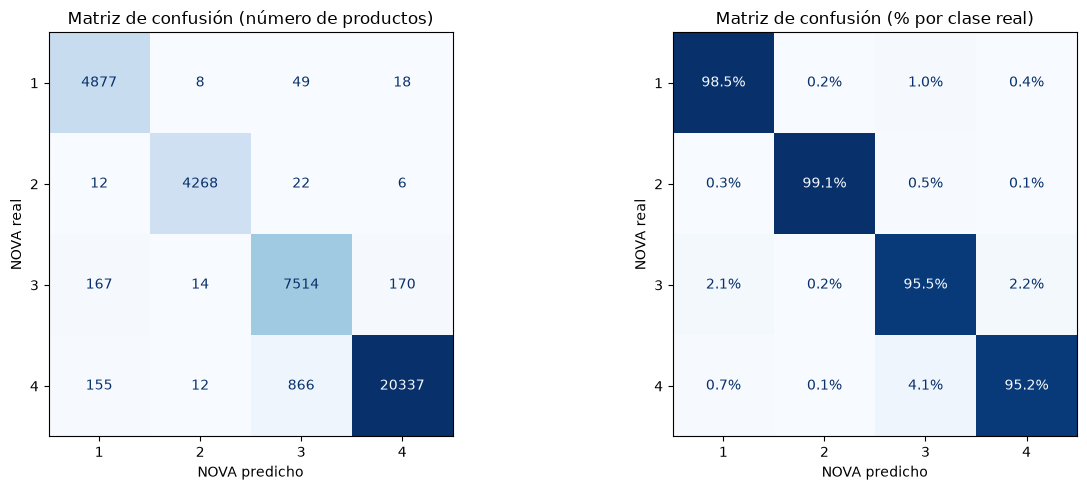

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Izquierda: número de productos
ConfusionMatrixDisplay.from_predictions(
    y_train, y_pred_cv, labels=[1, 2, 3, 4],
    values_format="d",
    cmap="Blues", ax=axes[0], colorbar=False,
)
axes[0].set_title("Matriz de confusión (número de productos)")

# Derecha: normalizada por fila = % de cada clase real (la diagonal es el recall)
ConfusionMatrixDisplay.from_predictions(
    y_train, y_pred_cv, labels=[1, 2, 3, 4], normalize="true",
    values_format=".1%", cmap="Blues", ax=axes[1], colorbar=False,
)
axes[1].set_title("Matriz de confusión (% por clase real)")

for ax in axes:
    ax.set_xlabel("NOVA predicho")
    ax.set_ylabel("NOVA real")

plt.tight_layout()
plt.show()

### 7.1 Resultados

**Macro F1 (CV): 0,961**

| NOVA | Precisión | Recall | F1 |
|---|---|---|---|
| 1 | 0,936 | 0,985 | 0,960 |
| 2 | 0,992 | 0,991 | 0,991 |
| 3 | 0,889 | 0,955 | 0,921 |
| 4 | 0,991 | 0,952 | 0,971 |

**Confusiones principales** (fuera de la diagonal de la matriz):

| Real → predicho | Productos | % de su clase |
|---|---|---|
| NOVA 4 → 3 | 866 | 4,1 % |
| NOVA 3 → 4 | 170 | 2,2 % |
| NOVA 3 → 1 | 167 | 2,1 % |
| NOVA 4 → 1 | 155 | 0,7 % |

**Qué clases se confunden y por qué:**
- La confusión principal es **NOVA 4 predicho como NOVA 3** (866 productos, 4,1 % de NOVA 4). La frontera entre "procesado" y "ultraprocesado" depende de detalles como un aroma o un emulsionante; si la lista de ingredientes está incompleta o el marcador no lo detecta, el producto parece NOVA 3.
- Los errores son casi siempre **entre clases vecinas** (3↔4, 3↔1). Las confusiones lejanas son raras: solo el 0,7 % de NOVA 4 se predice como NOVA 1.
- **NOVA 3 es la clase más difícil** (F1 0,921): recibe errores de todas las demás. Está "en medio" de la escala.
- **NOVA 2 es casi perfecta** (0,991), al contrario de lo que esperábamos en el EDA. Hipótesis: `sin_lista_ingredientes` y los marcadores de ingredientes culinarios (`tiene_aceite`, `tiene_azucar`, `tiene_sal`) la identifican casi sin error. Se comprueba en M04.
- Efecto de `class_weight="balanced"`: el modelo da más peso a las clases pequeñas, por eso NOVA 3 tiene más recall (0,955) que precisión (0,889). Prefiere predecir NOVA 3 de más antes que perder productos de esa clase.

El análisis detallado (variables importantes, ejemplos de productos mal clasificados) se hace en M04 (#11).

## Paso 8 · Guardar el modelo final y sus métricas

`GridSearchCV` reentrena automáticamente la mejor combinación (A) con **todo train** (`refit=True`, por defecto). Ese pipeline completo (preprocesado + Random Forest) es nuestro modelo final: `busqueda.best_estimator_`.

- **Modelo:** `models/random_forest.joblib`, con `compress=3` (≈ 16 MB). Guardamos el pipeline entero para que la app pueda predecir con valores en bruto. La carpeta `models/` no se sube al repo (`.gitignore`).
- **Métricas:** `reports/random_forest_metrics.json`, que sí se sube, para la comparación del M08.

El test sigue sin tocarse: se evalúa una sola vez en M08.

In [10]:
import json
import joblib
from pathlib import Path
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

# Modelo final: el pipeline A ya reentrenado con todo train por GridSearchCV
modelo_final = busqueda.best_estimator_
print("Parámetros elegidos:", busqueda.best_params_)

# Crear las carpetas si no existen
Path("../models").mkdir(exist_ok=True)
Path("../reports").mkdir(exist_ok=True)

# Guardar el pipeline completo comprimido
joblib.dump(modelo_final, "../models/random_forest.joblib", compress=3)

# Métricas por clase a partir de las predicciones de la validación cruzada (paso 7)
precision, recall, f1, _ = precision_recall_fscore_support(
    y_train, y_pred_cv, labels=[1, 2, 3, 4], zero_division=0
)

# Todo lo que necesita el M08 para comparar, en un diccionario
metricas = {
    "modelo": "RandomForestClassifier",
    "parametros": {"n_estimators": 200, "max_depth": None, "min_samples_leaf": 1,"class_weight": "balanced", "random_state": 42},
    "validacion": "StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42), groups=grupo_producto",

    # Medias del paso 5 (mismo modelo A)
    "f1_macro_train": round(tabla_cv["f1_train"].mean(), 4),
    "f1_macro_val": round(tabla_cv["f1_val"].mean(), 4),
    "f1_macro_val_std": round(tabla_cv["f1_val"].std(ddof=0), 4),
    "gap": round(tabla_cv["gap"].mean(), 4),

    # Precisión, recall y F1 de cada clase NOVA
    "por_clase": {
        str(clase): {"precision": round(p, 3), "recall": round(r, 3), "f1": round(f, 3)}
        for clase, p, r, f in zip([1, 2, 3, 4], precision, recall, f1)
    },
    
    # Matriz de confusión (filas = real, columnas = predicho)
    "matriz_confusion": confusion_matrix(y_train, y_pred_cv, labels=[1, 2, 3, 4]).tolist(),
}

# Guardar como JSON legible (indent=2) y con tildes bien escritas (ensure_ascii=False)
with open("../reports/random_forest_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metricas, f, indent=2, ensure_ascii=False)

print("Guardado: models/random_forest.joblib y reports/random_forest_metrics.json")

Parámetros elegidos: {'rf__max_depth': None, 'rf__min_samples_leaf': 1}
Guardado: models/random_forest.joblib y reports/random_forest_metrics.json


### 8.1 Conclusión del M03

- **Modelo elegido:** Random Forest sin límites de profundidad (200 árboles, `class_weight="balanced"`).
- **Macro F1 en validación: 0,961** (std 0,0024), **gap 3,1 %** (< 5 %).
- Recall por clase: NOVA 1 0,985 · NOVA 2 0,991 · NOVA 3 0,955 · NOVA 4 0,952.
- Confusión principal: NOVA 4 predicho como NOVA 3 (4 % de NOVA 4).
- **Limitación:** el F1 tan alto probablemente se debe a que Open Food Facts calcula NOVA con reglas sobre ingredientes y aditivos, y nuestros marcadores `tiene_*` reconstruyen parte de esas reglas. No es fuga de datos (la app también tendrá los ingredientes), pero el modelo aprende a imitar el algoritmo de OFF. Se analiza en M04 (#11).